## 不同活性空间下（3、4、5、6），六方相ZrO能量计算结果，bfgs参数优化

In [1]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(832359:126286609121280,MainProcess):2025-06-09-19:44:28.740.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [2]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [3]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 六方相ZrO

In [4]:
ZrO2d=get_mol(3)

[['Zr', [0.0, 0.0, 0.0]], ['O', [0.0, 3.0657299293969125, 0.8]]]
Hexagonal ZrO - Hartree-Fock energy: -575.9385060022055 Hartree.
Hexagonal ZrO - CCSD energy: -576.1026903963094 Hartree.


In [5]:
print("自动生成的文件名:", ZrO2d.filename)

自动生成的文件名: /home/jenkins/python_venv/scf_env/lib/python3.10/site-packages/openfermion/testing/data/O1-Zr1_gth-dzvp-molopt-sr_singlet_Hexagonal ZrO


In [6]:
ZrO2d.n_electrons

48

In [7]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=23, active_space_stop=26)

In [8]:
ansatz_circuit

┏━━━━━━━━━┓                                     ┏━━━━━━━━━━┓ ┏━━━┓               
q0: ──┨ RX(π/2) ┠───■─────────────────────────────■───┨ RX(7π/2) ┠─┨ H ┠───■─────────[red bold]↯[/]─
      ┗━━━━━━━━━┛   ┃                             ┃   ┗━━━━━━━━━━┛ ┗━━━┛   ┃           
                  ┏━┻━┓                         ┏━┻━┓                    ┏━┻━┓         
q1: ──────────────┨╺╋╸┠───■─────────────────■───┨╺╋╸┠────────────────────┨╺╋╸┠───■───[red bold]↯[/]─
                  ┗━━━┛   ┃                 ┃   ┗━━━┛                    ┗━━━┛   ┃     
      ┏━━━┓             ┏━┻━┓ ┏━━━━━━━━━┓ ┏━┻━┓       ┏━━━┓ ┏━━━━━━━━━┓        ┏━┻━┓   
q2: ──┨ H ┠─────────────┨╺╋╸┠─┨ RZ(-p0) ┠─┨╺╋╸┠───────┨ H ┠─┨ RX(π/2) ┠────────┨╺╋╸┠─[red bold]↯[/]─
      ┗━━━┛             ┗━━━┛ ┗━━━━━━━━━┛ ┗━━━┛       ┗━━━┛ ┗━━━━━━━━━┛        ┗━━━┛   
                                                                                       
q3: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                                                                                       
q4: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                                                                                       
q5: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                             ┏━━━┓ ┏━━━┓                                               
q0: ─────────────────────■───┨ H ┠─┨ H ┠────────────────■───────────────[red bold]↯[/]─             
                         ┃   ┗━━━┛ ┗━━━┛                ┃                              
                       ┏━┻━┓ ┏━━━┓                    ┏━┻━┓                            
q1: ───────────────■───┨╺╋╸┠─┨ H ┠────────────────────┨╺╋╸┠───■─────────[red bold]↯[/]─             
                   ┃   ┗━━━┛ ┗━━━┛                    ┗━━━┛   ┃                        
      ┏━━━━━━━━┓ ┏━┻━┓       ┏━━━━━━━━━━┓ ┏━━━━━━━━━┓       ┏━┻━┓                      
q2: ──┨ RZ(p0) ┠─┨╺╋╸┠───────┨ RX(7π/2) ┠─┨ RX(π/2) ┠───────┨╺╋╸┠───■───[red bold]↯[/]─             
      ┗━━━━━━━━┛ ┗━━━┛       ┗━━━━━━━━━━┛ ┗━━━━━━━━━┛       ┗━━━┛   ┃                  
                             ┏━━━┓                                ┏━┻━┓                
q3: ─────────────────────────┨ H ┠────────────────────────────────┨╺╋╸┠─[red bold]↯[/]─             
                             ┗━━━┛                                ┗━━━┛                
                                                                                       
q4: ────────────────────────────────────────────────────────────────────[red bold]↯[/]─             
                                                                                       
                                                                                       
q5: ────────────────────────────────────────────────────────────────────[red bold]↯[/]─             
                                                                                       
                                        ┏━━━┓ ┏━━━━━━━━━┓                              
q0: ────────────────────────────────■───┨ H ┠─┨ RX(π/2) ┠──────────■───────────────[red bold]↯[/]─  
                                    ┃   ┗━━━┛ ┗━━━━━━━━━┛          ┃                   
                                  ┏━┻━┓ ┏━━━┓ ┏━━━━━━━━━┓        ┏━┻━┓                 
q1: ──────────────────────────■───┨╺╋╸┠─┨ H ┠─┨ RX(π/2) ┠────────┨╺╋╸┠───■─────────[red bold]↯[/]─  
                              ┃   ┗━━━┛ ┗━━━┛ ┗━━━━━━━━━┛        ┗━━━┛   ┃             
                            ┏━┻━┓       ┏━━━━━━━━━━┓ ┏━━━━━━━━━┓       ┏━┻━┓           
q2: ────────────────────■───┨╺╋╸┠───────

In [9]:
n_electrons

2

In [10]:
hamiltonian_QubitOp

-575.7417 [] +
   0.5948 [Z0] +
   0.0429 [X0 Z1 X2] +
   0.0429 [Y0 Z1 Y2] +
  -0.0137 [X0 Z1 Z2 Z3 X4] +
  -0.0137 [Y0 Z1 Z2 Z3 Y4] +
   0.5948 [Z1] +
   0.0429 [X1 Z2 X3] +
   0.0429 [Y1 Z2 Y3] +
  -0.0137 [X1 Z2 Z3 Z4 X5] +
  -0.0137 [Y1 Z2 Z3 Z4 Y5] +
   0.3563 [Z2] +
  -0.0041 [X2 Z3 X4] +
  -0.0041 [Y2 Z3 Y4] +
   0.3563 [Z3] +
  -0.0041 [X3 Z4 X5] +
  -0.0041 [Y3 Z4 Y5] +
   0.0355 [Z4] +
   0.0355 [Z5] +
   0.2216 [Z0 Z1] +
   0.0349 [X0 X2] +
   0.0349 [Y0 Y2] +
  -0.0102 [X0 Z2 Z3 X4] +
  -0.0102 [Y0 Z2 Z3 Y4] +
   0.0349 [Z0 X1 Z2 X3] +
   0.0349 [Z0 Y1 Z2 Y3] +
   0.0081 [X0 Y1 Y2 X3] +
  -0.0081 [Y0 Y1 X2 X3] +
  -0.0081 [X0 X1 Y2 Y3] +
   0.0081 [Y0 X1 X2 Y3] +
   0.0027 [X0 Y1 Y3 X4] +
   0.0027 [X0 X1 X3 X4] +
   0.0027 [Y0 Y1 Y3 Y4] +
   0.0027 [Y0 X1 X3 Y4] +
  -0.0102 [Z0 X1 Z2 Z3 Z4 X5] +
  -0.0102 [Z0 Y1 Z2 Z3 Z4 Y5] +
  -0.0027 [X0 Y1 Y2 Z3 Z4 X5] +
   0.0027 [Y0 Y1 X2 Z3 Z4 X5] +
   0.0027 [X0 X1 Y2 Z3 Z4 Y5] +
  -0.0027 [Y0 X1 X2 Z3 Z4 Y5] +
   0.0012 [X0 Y1 Y4

In [11]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

               Circuit Summary               
╭──────────────────────┬────────────────────╮
│ Info                 │ value              │
├──────────────────────┼────────────────────┤
│ Number of qubit      │ 6                  │
├──────────────────────┼────────────────────┤
│ Total number of gate │ 602                │
│ Barrier              │ 160                │
│ Noise Channel        │ 0                  │
│ Measurement          │ 0                  │
├──────────────────────┼────────────────────┤
│ Parameter gate       │ 40                 │
│ 5 ansatz parameters  │ p0, p2, p1, p3, p4 │
╰──────────────────────┴────────────────────╯

Number of parameters: 5


In [12]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)


In [40]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g




In [41]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -575.5487822894012
Step: 10,	energy: -575.9293911558823
Step: 15,	energy: -575.940713585141
Step: 20,	energy: -575.9419077899195
Step: 25,	energy: -575.9419343213872


/tmp/ipykernel_832359/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


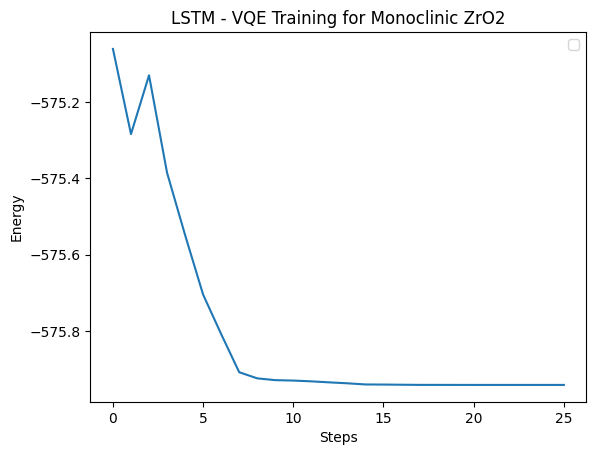

Estimated ground state energy of Monoclinic ZrO2: -575.941934321424


In [42]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [17]:
print('L1=',energy_list)

L1= [-574.9634817475843, -575.6263480625498, -575.7432390868231, -575.8478127194132, -575.8020950300504, -575.8921884425455, -575.8936070316487, -575.8963698857749, -575.9053523523703, -575.9132722949066, -575.9133036342724, -575.9133042271665, -575.9133052028717, -575.9133068971832, -575.9133098226679, -575.9133143917286, -575.9133179686364, -575.9133187517199, -575.9133191113463, -575.9133191755931, -575.9133192841965, -575.9133194795417, -575.9133198409027, -575.9133205157289, -575.913321776309, -575.9133241225517, -575.9133284877212, -575.9133367937574, -575.9133543027937, -575.9134480228986, -575.9019656859788, -575.9134490896738, -575.9134512339245, -575.9134595834905, -575.9134881287083, -575.9135542768787, -575.9136494292958, -575.9136484176976, -575.913675045082, -575.9136774950663, -575.9136819620883, -575.9136903081979, -575.9137056846175, -575.913730376455, -575.9137601340182, -575.9138178096242, -575.9139115769239, -575.9139044072208, -575.9140081780308, -575.9141828317249

In [36]:
energy_list

[-577.6495368001697,
 -578.172120075759,
 -578.2530403728119,
 -578.2908914454727,
 -578.2707378519632,
 -578.3091270743191,
 -578.3319102531357,
 -578.335321037067,
 -578.3368662201602,
 -578.3394646550095,
 -578.3419434811514,
 -578.3422778861625,
 -578.3423095809684,
 -578.3423061426437,
 -578.3423106842079,
 -578.3423108368895,
 -578.3423108447697,
 -578.3423108452862]

## 下面这个是一个比较好的 3轨道优化结果，27,28,29o 2e

In [43]:
     ##一个比较好的结果

In [83]:
L1= [-574.4712797250351, -575.2796938494639, -575.6849113723446, -575.0849943664119, -575.8214848586975, -575.7700798124843, -575.8762091677595, -575.7890063857548, -575.8897259098401, -575.8910952152155, -575.8937228441885, -575.9016013821184, -575.9207808877202, -575.9335734813935, -575.938077940061, -575.9379577342374, -575.9381491280532, -575.9382227354358, -575.9382767679042, -575.9383729274987, -575.9385143614769, -575.9385816195708, -575.938602426952, -575.9386050872316, -575.9386055517015, -575.9386058010128, -575.9386062621275, -575.9386071310288, -575.9386087698966, -575.9386118057298, -575.9386169737852, -575.9386215528465, -575.9386246238178, -575.9386295160923, -575.9386324343144, -575.9386324931446, -575.9386324954874, -575.938632496653, -575.9386324988632, -575.9386325031013, -575.9386325112124, -575.9386325265934, -575.9386325552153, -575.9386326068375, -575.9386326955143, -575.9386328387939, -575.9386330643925, -575.9386334367221, -575.9386340652507, -575.9386350639152, -575.9386362647435, -575.9386368254914, -575.9386369862267, -575.9386369883847]

/tmp/ipykernel_832359/3920743744.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


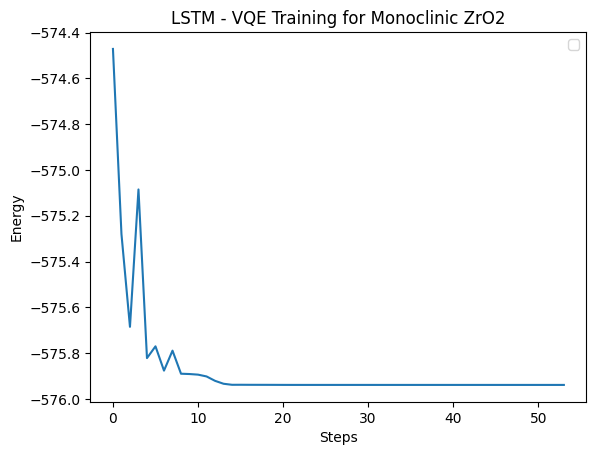

Estimated ground state energy of Monoclinic ZrO2: -575.9386369883847


In [84]:
# 绘制能量变化曲线
plt.figure()
plt.plot(L1)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {L1[-1]}")

## 4轨道

In [48]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=26)

In [49]:
n_electrons

4

In [50]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                          Circuit Summary                           
╭──────────────────────┬───────────────────────────────────────────╮
│ Info                 │ value                                     │
├──────────────────────┼───────────────────────────────────────────┤
│ Number of qubit      │ 8                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Total number of gate │ 2692                                      │
│ Barrier              │ 640                                       │
│ Noise Channel        │ 0                                         │
│ Measurement          │ 0                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Parameter gate       │ 160                                       │
│ 14 ansatz parameters │ p0, p4, p1, p5, p2, p6, p3, p7, p8, p9... │
╰──────────────────────┴───────────────────────────────────────────╯

Number of parameters: 14


In [85]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [86]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [87]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -575.7889975793452
Step: 10,	energy: -575.7708279545097
Step: 15,	energy: -575.9398822592925
Step: 20,	energy: -575.941171708804
Step: 25,	energy: -575.941289879976
Step: 30,	energy: -575.9415285931747
Step: 35,	energy: -575.9415572757512
Step: 40,	energy: -575.9415624287492
Step: 45,	energy: -575.9415860358702
Step: 50,	energy: -575.9416145261786
Step: 55,	energy: -575.9416186728909
Step: 60,	energy: -575.9416428472501
Step: 65,	energy: -575.941644113004
Step: 70,	energy: -575.9416447566382
Step: 75,	energy: -575.9416527755963
Step: 80,	energy: -575.9416593371108
Step: 85,	energy: -575.9416593572923
Step: 90,	energy: -575.94165950024
Step: 95,	energy: -575.941660413037


/tmp/ipykernel_832359/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


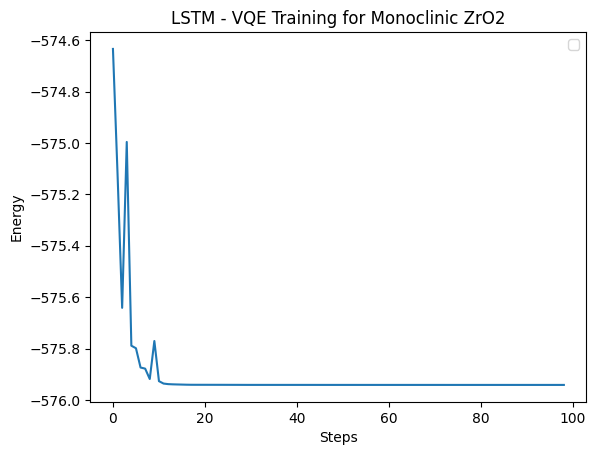

Estimated ground state energy of Monoclinic ZrO2: -575.9416605442128


In [88]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [64]:
energy_list[0:25]

[-574.9644051086688,
 -575.2436073368704,
 -575.8188341857303,
 -575.7569505418447,
 -575.9088899539976,
 -575.9308848855818,
 -575.9004955535917,
 -575.9362480182074,
 -575.9348982295446,
 -575.937998109504,
 -575.938265181377,
 -575.9384264631384,
 -575.9384836324591,
 -575.9384982983654,
 -575.9385235382339,
 -575.9385663241613,
 -575.9386533986511,
 -575.9382750492756,
 -575.9388061859138,
 -575.9287394612148,
 -575.9388337014129,
 -575.9388591985836,
 -575.938909463577,
 -575.9390729509166,
 -575.9393125375915]

In [ ]:
Step: 200,	energy: -575.9417877712388
Step: 205,	energy: -575.9417881257656
Step: 210,	energy: -575.9417886677892
Step: 215,	energy: -575.9417976981756
Step: 220,	energy: -575.9418178301877
Step: 225,	energy: -575.9418192764712

In [ ]:
-578.3513665290346

In [89]:
print('L4=',energy_list)

L4= [-574.6343045644858, -575.1214912096414, -575.6417296782569, -574.9962658747745, -575.7889975793452, -575.7989534738484, -575.8739979593552, -575.8782479589022, -575.9186406993672, -575.7708279545097, -575.9269901002709, -575.9363783663393, -575.9385394575655, -575.9393767186059, -575.9398822592925, -575.9403491083674, -575.9408148579082, -575.9410943837119, -575.94114676611, -575.941171708804, -575.9411898542274, -575.9412187747328, -575.9412462168508, -575.9412620081004, -575.941289879976, -575.9413342472324, -575.9413798234499, -575.9414118159074, -575.9414648098489, -575.9415285931747, -575.9415360247881, -575.9415383023878, -575.9415422169213, -575.9415487528184, -575.9415572757512, -575.9415598650943, -575.9415610573196, -575.9415614720117, -575.9415618143493, -575.9415624287492, -575.941563561026, -575.9415656508432, -575.9415694398258, -575.9415759919632, -575.9415860358702, -575.9415960922283, -575.9416056434939, -575.9416138933166, -575.9416143645565, -575.9416145261786, 

## 一个比较好的4轨道优化结果 26,27,28,29o 4e

In [90]:
L4= [-574.6343045644858, -575.1214912096414, -575.6417296782569, -574.9962658747745, -575.7889975793452, -575.7989534738484, -575.8739979593552, -575.8782479589022, -575.9186406993672, -575.7708279545097, -575.9269901002709, -575.9363783663393, -575.9385394575655, -575.9393767186059, -575.9398822592925, -575.9403491083674, -575.9408148579082, -575.9410943837119, -575.94114676611, -575.941171708804, -575.9411898542274, -575.9412187747328, -575.9412462168508, -575.9412620081004, -575.941289879976, -575.9413342472324, -575.9413798234499, -575.9414118159074, -575.9414648098489, -575.9415285931747, -575.9415360247881, -575.9415383023878, -575.9415422169213, -575.9415487528184, -575.9415572757512, -575.9415598650943, -575.9415610573196, -575.9415614720117, -575.9415618143493, -575.9415624287492, -575.941563561026, -575.9415656508432, -575.9415694398258, -575.9415759919632, -575.9415860358702, -575.9415960922283, -575.9416056434939, -575.9416138933166, -575.9416143645565, -575.9416145261786, -575.9416147630277, -575.9416150971492, -575.941615677088, -575.9416167327954, -575.9416186728909, -575.9416221750305, -575.9416280981537, -575.9416359829578, -575.9416401190931, -575.9416428472501, -575.941643846073, -575.9416440480637, -575.9416440889223, -575.9416440973529, -575.941644113004, -575.941644142207, -575.9416441962154, -575.9416442940842, -575.9416444659903, -575.9416447566382, -575.9416452346384, -575.9416460241251, -575.9416473460236, -575.9416495166479, -575.9416527755963, -575.9416559187399, -575.9416581473254, -575.9416591611069, -575.9416592702742, -575.9416593371108, -575.9416593486362, -575.9416593516652, -575.9416593525361, -575.9416593541702, -575.9416593572923, -575.9416593632718, -575.9416593746352, -575.9416593958535, -575.9416594342667, -575.94165950024, -575.941659605284, -575.9416597646112, -575.9416600025636, -575.9416603131291, -575.941660413037, -575.9416605167784, -575.9416605426337, -575.9416605440089, -575.9416605442128]

In [35]:
Menergy4 = energy_list

## 5轨道，22,23,24,25,26

In [91]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [92]:
n_electrons

4

In [93]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [94]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [150]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [151]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -574.0483367655404
Step: 10,	energy: -574.7696896248398
Step: 15,	energy: -575.6698098004941
Step: 20,	energy: -575.9109630178989
Step: 25,	energy: -575.93774320678
Step: 30,	energy: -575.9385230781547
Step: 35,	energy: -575.9385256421656
Step: 40,	energy: -575.9385333467771
Step: 45,	energy: -575.9385334396708
Step: 50,	energy: -575.938534315387
Step: 55,	energy: -575.9385381886398
Step: 60,	energy: -575.9385504496855
Step: 65,	energy: -575.9385682877158
Step: 70,	energy: -575.9385747024583
Step: 75,	energy: -575.9385793880467
Step: 80,	energy: -575.9385805329206
Step: 85,	energy: -575.9385806360926
Step: 90,	energy: -575.9385822442949
Step: 95,	energy: -575.9385044176659
Step: 100,	energy: -575.9386022416137
Step: 105,	energy: -575.9386408954191
Step: 110,	energy: -575.9386495136459
Step: 115,	energy: -575.9386499391743
Step: 120,	energy: -575.9386522722363
Step: 125,	energy: -575.938712582246
Step: 130,	energy: -575.93907769031
Step: 135,	energy: -575.9392934871643


/tmp/ipykernel_832359/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


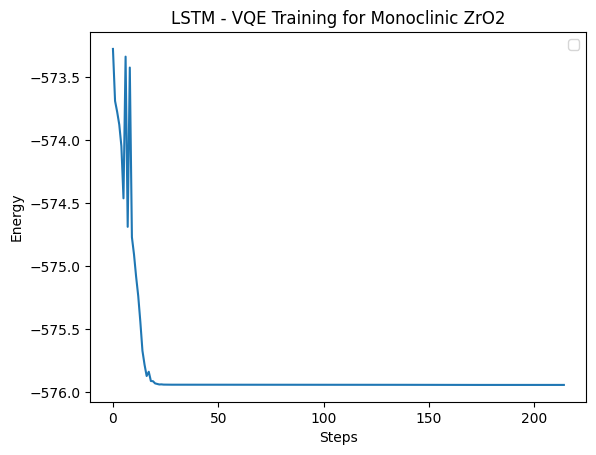

Estimated ground state energy of Monoclinic ZrO2: -575.9402667992151


In [152]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [154]:
L5=[-573.7807370131877,-574.2867127899169,-573.8549045094636,-574.3665497880475,-574.5300730494412,-574.5743978852367,-574.6409822251334,-574.8229771766312,-575.17324403982,
 -574.9020918483534,-575.3500759814686,-575.4354000308382,-575.5294483108509,-575.680601081307,-575.8124225154289,-575.7942069886486,-575.8720114253056,
 -575.8639415269963,-575.9004070462439,-575.9144218356965,-575.9260516675168,-575.9249476215252,-575.9306050268397,-575.9335406600092,-575.9340745727729,-575.9383818370625,
 -575.9385188315479,-575.9385225627623,-575.9385230781547,-575.9385231811208,-575.9385233765059,-575.9385237467478,-575.9385244331996,-575.9385256421656,
 -575.9385275315253,-575.9385294308433,-575.9385309837173]

In [101]:
energy_list[0:25]

[-573.7807370131877,
 -574.2867127899169,
 -573.8549045094636,
 -574.3665497880475,
 -574.5300730494412,
 -574.5743978852367,
 -574.6409822251334,
 -574.8229771766312,
 -575.17324403982,
 -574.9020918483534,
 -575.3500759814686,
 -575.4354000308382,
 -575.5294483108509,
 -575.680601081307,
 -575.8124225154289,
 -575.7942069886486,
 -575.8720114253056,
 -575.8639415269963,
 -575.9004070462439,
 -575.9144218356965,
 -575.9260516675168,
 -575.9249476215252,
 -575.9306050268397,
 -575.9335406600092,
 -575.9340745727729]

In [136]:
energy_list[0:30]

[-573.3914749440388,
 -573.3029252688393,
 -573.8034633462653,
 -573.8311330755957,
 -573.8841148092669,
 -573.9864462900547,
 -574.2261725502733,
 -574.3382335038874,
 -574.5308534585179,
 -574.625130034226,
 -574.784374385607,
 -575.0405527134958,
 -575.3980132135879,
 -575.001824353671,
 -575.5407975953564,
 -575.7179154750254,
 -575.7382822502867,
 -575.7741606010505,
 -575.8309695441834,
 -575.8677661232932,
 -575.8900427401145,
 -575.9034915285515,
 -575.9066364255866,
 -575.911989254702,
 -575.9193607746287,
 -575.9238358156949,
 -575.9262690897884,
 -575.9298731842034,
 -575.9337106399197,
 -575.9355614058063]

In [155]:
-578.3517871563753

-578.3517871563753

In [200]:
print('L5=',energy_list)

L5= [-577.1500321555817, -577.3387013472047, -577.4235385072086, -577.5824847417323, -577.715173326868, -577.9190410565019, -578.0890302495108, -578.1078542728949, -578.1353030908974, -578.1665466121771, -578.1546591897503, -578.1751972424778, -578.1764933565646, -578.178077183857, -578.1782640149346, -578.1782745695352, -578.1782923562025, -578.1783113179226, -578.178315782022, -578.1783242974388, -578.1783408918134, -578.1783951313465, -578.1785071818479, -578.1785941229349, -578.1786982988457, -578.1788011872212, -578.1788345743172, -578.1788457285369, -578.1788545791559, -578.1788703734608, -578.178899594705, -578.1789540294055, -578.1790537782267, -578.1792233031027, -578.1794173759649, -578.1795580637063, -578.1797994113252, -578.1800265027589, -578.1800807790895, -578.1801092496931, -578.1801347590117, -578.1801677028759, -578.1802329088226, -578.1804664088402, -578.180924733802, -578.1810417636033, -578.1812030821554, -578.1814037389562, -578.1814943414007, -578.1815402058614, 

## 好结果

In [115]:
L5= [-577.1500321555817, -577.3387013472047, -577.4235385072086, -577.5824847417323, -577.715173326868, -577.9190410565019, -578.0890302495108, -578.1078542728949, -578.1353030908974, -578.1665466121771, -578.1546591897503, -578.1751972424778,-578.1800265027589,-578.1890708109623, -578.1913947293416, -578.1946123678708, -578.1960131996644, -578.1983437553195, -578.2215491509121, -578.2333542482406, -578.2368847544542, -578.2409355476082, -578.2527747943748, -578.2711125923976, -578.2983198814122, -578.3044620180672, -578.3137772175544, -578.3138652060805, -578.3187115435671, -578.3231345014101, -578.3274611021302, -578.3279428324978, -578.3288505327694, -578.3304447417784, -578.3325326448783, -578.3331608933635, -578.3339727854278, -578.3344651571965, -578.3347541802198, -578.3351737266617, -578.3358820047126, -578.3371050023122, -578.3391023489603, -578.3348128073017, -578.3397235598626, -578.3407866470095, -578.3421105147002, -578.3422211685149, -578.3422567874353, -578.3422942835475, -578.3423205665226, -578.342352229227, -578.342394922672, -578.3424375519814, -578.3424569417608, -578.3424651451795, -578.3424695631971, -578.3424752812901, -578.3424842567024, -578.3424948945438, -578.3424991991105, -578.3425012119727, -578.3425033147115, -578.3425065876911, -578.3425116383809, -578.3425181824432, -578.3425238124725, -578.3425294173254, -578.3425354314786, -578.3425399000167, -578.3425422916604, -578.3425452704992, -578.3425496517794, -578.3425563871252, -578.3425630480098, -578.3425645453899, -578.3425649738435, -578.3425653729959, -578.3425660682198, -578.3425672883058, -578.3425693298353, -578.3425722075759, -578.3425739261568, -578.3425751386474, -578.3425760213297, -578.3425771564155, -578.3425789954864, -578.3425817958989, -578.342584301519, -578.3425851796395, -578.3425853536734, -578.3425853666416, -578.3425853691375, -578.34258537055, -578.3425853710494, -578.3425853713037, -578.3425853717239, -578.3425853724747, -578.3425853738646, -578.342585376445, -578.3425853812105, -578.3425853898916, -578.3425854054112, -578.3425854325505, -578.3425854791858, -578.3425855592701, -578.3425856984261, -578.3425859318378, -578.3425861982047, -578.3425866862462, -578.3425875078012, -578.342588476397, -578.342586654453, -578.3425888021632, -578.3425892598082, -578.3425896724256, -578.3425901025252, -578.3425906028798, -578.342591408244, -578.3425901845654, -578.342591677788, -578.3425919744534, -578.342592202615, -578.3425922159355, -578.3425922419881, -578.3425923285567, -578.3425924956763, -578.34259266618, -578.3425929334619, -578.3425933778012, -578.3425941410212, -578.3425955766761, -578.3425750165418, -578.3425958766225, -578.342596018459, -578.342596272235, -578.3425966638961, -578.3425968472757, -578.3425970514731, -578.3425972962085, -578.3425977063264, -578.3425979647712, -578.3425980296689, -578.3425984228949, -578.3425987673356, -578.3425986979069, -578.3425988739359, -578.3425990434339, -578.3425993020123, -578.342599507966, -578.3425997660249, -578.3425999277191, -578.3426000935644, -578.3426003465805, -578.3426006720307, -578.3426011360651, -578.3426015296799, -578.342601722986, -578.3426020835011, -578.3426013964787, -578.3426022525778, -578.342602401729, -578.3426025252672, -578.3426027129944, -578.3426029163768, -578.3426029895601, -578.3426030562658, -578.3426032703003, -578.3426036263493, -578.342604196829, -578.3426047215736, -578.3426054832411, -578.3426064499946, -578.342607510422, -578.3426072574802, -578.3426076801817, -578.3426079086005, -578.3426079914318, -578.3426080009242, -578.3426080141737, -578.3426080304096, -578.3426080590598, -578.3426081137, -578.3426082188735, -578.3426085333938, -578.3426090785799, -578.3426098092747, -578.3426105359727, -578.3426107474377, -578.3426106925976, -578.3426108297725, -578.342610855403, -578.3426108623333, -578.3426108645787, -578.3426108651317]


In [59]:
Menergy5 = energy_list

## 6轨道，21,22,23,24,25,26

In [181]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=21, active_space_stop=27)

In [182]:
n_electrons

6

In [183]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                            Circuit Summary                             
╭──────────────────────┬───────────────────────────────────────────────╮
│ Info                 │ value                                         │
├──────────────────────┼───────────────────────────────────────────────┤
│ Number of qubit      │ 12                                            │
├──────────────────────┼───────────────────────────────────────────────┤
│ Total number of gate │ 16338                                         │
│ Barrier              │ 3312                                          │
│ Noise Channel        │ 0                                             │
│ Measurement          │ 0                                             │
├──────────────────────┼───────────────────────────────────────────────┤
│ Parameter gate       │ 828                                           │
│ 54 ansatz parameters │ p0, p9, p1, p10, p2, p11, p3, p12, p4, p13... │
╰──────────────────────┴───────────────────────────────────────────────╯

Number of parameters: 54


In [184]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [200]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [201]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -574.7428299509255
Step: 10,	energy: -575.6000940301265
Step: 15,	energy: -575.9033735183899
Step: 20,	energy: -575.9361390941983
Step: 25,	energy: -575.9381918631567
Step: 30,	energy: -575.9385053768362
Step: 35,	energy: -575.9385109649027
Step: 40,	energy: -575.9385110315134
Step: 45,	energy: -575.9385110180478
Step: 50,	energy: -575.9385116606006
Step: 55,	energy: -575.9385137149743
Step: 60,	energy: -575.9385199288829
Step: 65,	energy: -575.9385494261635
Step: 70,	energy: -575.9385534665198
Step: 75,	energy: -575.9385541937545
Step: 80,	energy: -575.9385695806124
Step: 85,	energy: -575.9386546226943
Step: 90,	energy: -575.9386896725539
Step: 95,	energy: -575.9387679783306
Step: 100,	energy: -575.9387863092811
Step: 105,	energy: -575.9388184454446
Step: 110,	energy: -575.9389069122234
Step: 115,	energy: -575.9390002241828
Step: 120,	energy: -575.9390290777634
Step: 125,	energy: -575.9390537693802
Step: 130,	energy: -575.9390658916144
Step: 135,	energy: -575.93909865

/tmp/ipykernel_832359/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


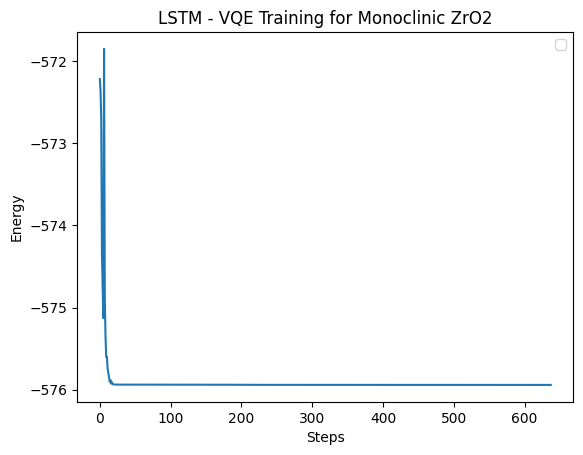

Estimated ground state energy of Monoclinic ZrO2: -575.9421331633905


In [202]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [ ]:
-575.9413810185458

In [220]:
print('L6=',energy_list)

L6= [-576.605029719118, -576.931891564637, -576.8654391627355, -577.0761637768662, -577.332483866488, -577.631472195477, -577.9273868874791, -578.0060580244306, -578.1171017031669, -578.2526983276879, -578.1968264011516, -578.3096628759041, -578.2801864120631, -578.3197600918746, -578.3137039373074, -578.3236261264034, -578.3257518736674, -578.3284583405808, -578.329087707257, -578.3298497832589, -578.329540083714, -578.3299811346761, -578.3301324479419, -578.3302060536369, -578.330254762672, -578.3302746515816, -578.3302875688212, -578.3302928635079, -578.3302955002886, -578.3302975393395, -578.3302996127395, -578.3303007705446, -578.330301782434, -578.3303035782377, -578.330306897305, -578.3303131207441, -578.3303247825329, -578.3303462330691, -578.3303832251868, -578.3304341813947, -578.3304782349217, -578.3305235864322, -578.3305360343567, -578.3305413134767, -578.3305429439353, -578.3305434416245, -578.330544148456, -578.3305453798201, -578.3305475936464, -578.3305515913116, -578.

In [103]:
L6=[-605.672301047877,-606.5444939553223,-607.4516068626691,-606.8206153485895,-607.7738003404322,-608.0930567990422,-607.9429015214613,-608.1082359419971,
 -608.10264535389,-608.1145218989572,-608.1154192311499,-608.1169598460074,-608.1187802517908,-608.1152184183702,-608.1192471580546,
 -608.1194431770058,-608.1195144395804,-608.1195830964606,-608.119602680474,-608.1196115682925,-608.1196140338002,-608.1196148442001,
 -608.1196151903938,-608.1196163470137,-608.1196174068508,-608.1196184315328,-608.1196194393417,-608.1196198404411,-608.1196199420286,-608.1196154447807,
 -608.1196254497687,-608.1196354589691,-608.1196654759829,-608.11968155072706,-608.119695564191,-608.1197056664327,-608.1197158491435,
 -608.1197261824265,-608.1197368374421,-608.1197405240147,-608.11975358861655,-608.1197610327018,-608.1197899881944,-608.11939234694424,
 -608.11981858447262,-608.119820405908,-608.1198411974679,-608.1198527011782,-608.1199024568, -608.11993698777984,
 -608.11995699310334,-608.11996700181475,-608.11996751531499,-608.119967703334617,-608.119968705019383,-608.119969705835852,-608.11997015947544,-608.119986705954737,
   -608.1199902167,-608.119993986736,-608.12000377656,-608.1200560844345]

/tmp/ipykernel_798557/2289154007.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


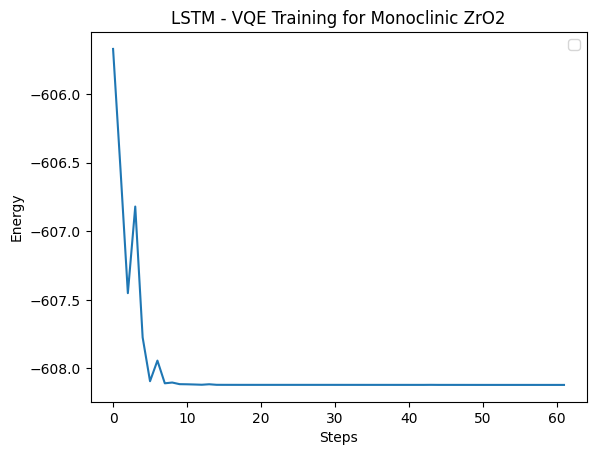

Estimated ground state energy of Monoclinic ZrO2: -608.1200560844345


In [104]:
# 绘制能量变化曲线
plt.figure()
plt.plot(L6)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {L6[-1]}")

In [136]:
L6=[-604.0002159008357,-605.0022810188616,-604.5509883490627,-605.5699723620663,-605.9143813186827,-606.1785268678395,-606.4679150344735,
-606.6031343857064,-606.708327627045,-606.855908805653,-607.082280290574,-607.3231046807604,-607.0461674790116,-607.4111269012307,
 -607.5173707318992,-607.5547479932594,-607.6144983744014,-607.7169176162487,-607.8619947912977,-607.684276371614,-607.9194987017919,
-607.9819184508173,-608.022782087438,-608.0594850487275,-608.0724003492776,-608.0877550138488,-608.0942819545259,-608.0984852774203,-608.1005361831996,-608.1034312880773,
 -608.1071124182358,-608.1100949832506,-608.1129654401137,-608.1154036088737,-608.1165320716494,-608.1173012721271,-608.1176778385843,
 -608.1179213069967,-608.118167705678,-608.1184204523523,-608.1186063275215,-608.1186856354029,-608.1187366424463,-608.118892308235,-608.1189846581336,
 -608.1190958285723,-608.1192350127545,-608.119421029637,-608.1194593599151,-608.1195123574197,-608.1195326496365,-608.1195411404894,
 -608.1195528393284,-608.1195719713877,-608.1195931770507,-608.119597514687,-608.1196041119626,-608.1196064689734,-608.1196074000156,
 -608.1196077669988,-608.1196082432696,-608.1196083645185,-608.1196083879116,-608.1196083898524,-608.1196083911369,-608.119608391331,
 -608.1196083916882,-608.1196083923692,-608.1196083936285,-608.1196083959247,-608.119608399967,-608.1196084066042,-608.1196084164322,
 -608.119608426772,-608.1196084392192,-608.1196084451785,-608.1196084458404,-608.1196084459093,-608.1196084459457]

[-604.0002159008357,
 -605.0022810188616,
 -604.5509883490627,
 -605.5699723620663,
 -605.9143813186827,
 -606.1785268678395,
 -606.4679150344735,
 -606.6031343857064,
 -606.708327627045,
 -606.855908805653,
 -607.082280290574,
 -607.3231046807604,
 -607.0461674790116,
 -607.4111269012307,
 -607.5173707318992,
 -607.5547479932594,
 -607.6144983744014,
 -607.7169176162487,
 -607.8619947912977,
 -607.684276371614,
 -607.9194987017919,
 -607.9819184508173,
 -608.022782087438,
 -608.0594850487275,
 -608.0724003492776,
 -608.0877550138488,
 -608.0942819545259,
 -608.0984852774203,
 -608.1005361831996,
 -608.1034312880773,
 -608.1071124182358,
 -608.1100949832506,
 -608.1129654401137,
 -608.1154036088737,
 -608.1165320716494,
 -608.1173012721271,
 -608.1176778385843,
 -608.1179213069967,
 -608.118167705678,
 -608.1184204523523,
 -608.1186063275215,
 -608.1186856354029,
 -608.1187366424463,
 -608.118892308235,
 -608.1189846581336,
 -608.1190958285723,
 -608.1192350127545,
 -608.119421029637,


/tmp/ipykernel_798557/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


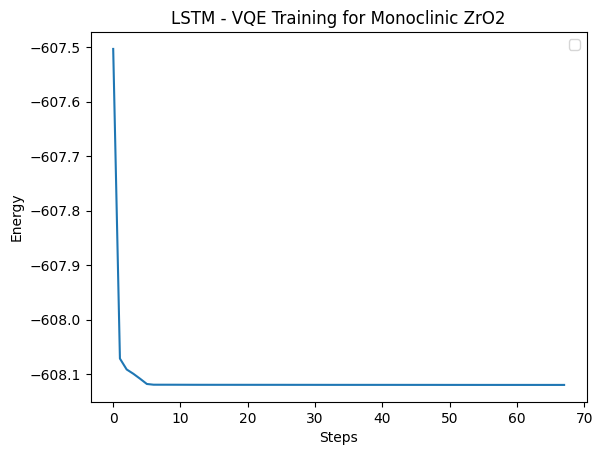

Estimated ground state energy of Monoclinic ZrO2: -608.1200560772278


In [116]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")